# MSCS 634 – Project Deliverable 2
## Regression Modeling and Performance Evaluation
### Dataset: IBM Telco Customer Churn (cleaned in Deliverable 1)

**Course:** MSCS 634
**Authors:** Pranavi Balakulla, Sandeep Reddy Banda, Sowmya Cheruku, Vineela Reddy Karnatakam
**Project:** Advanced Data Mining for Data-Driven Insights and Predictive Modeling

---

**Notebook roadmap**

1. Choosing the regression target (and avoiding target leakage)
2. Setup and data loading
3. Understanding the target
4. Feature engineering
5. Train/test split and model definitions
6. Cross-validation (5-fold) on raw vs engineered features
7. Hold-out test evaluation
8. Visual comparison of model performance
9. Model interpretation (what drives lifetime revenue?)
10. Summary of results, insights, and challenges

## 1. Choosing the Regression Target

**Business question:** *How much revenue is a customer worth, given their plan and profile?*
We predict **`TotalCharges`** — the total amount a customer has been billed over their relationship with the company
(their lifetime revenue to date). Estimating customer value lets the business decide **how much it can afford to spend
to retain each customer**, which pairs directly with the churn model in Deliverable 3 (revenue at risk = churn
probability × customer value).

**Why not the target planned in Deliverable 1?** Deliverable 1 proposed predicting `MonthlyCharges`. Before building
models we ran two quick sanity checks (code below):

| Candidate | Check | Result | Problem |
|---|---|---|---|
| `MonthlyCharges` from the services a customer buys | 5-fold CV R² of a plain linear regression | ≈ 0.999 | The bill is a **price-list lookup** (base price + add-on prices). There is nothing left to predict, every model ties, and model comparison is meaningless. |
| `TotalCharges` using **tenure** as a feature | 5-fold CV R² | ≈ 0.999 | `TotalCharges ≈ tenure × MonthlyCharges`. Using tenure is **target leakage**: the answer is built from the inputs. |
| **`TotalCharges` without tenure** | 5-fold CV R² | ≈ 0.75 | A realistic, non-trivial problem: the model must infer how valuable a customer is from contract, services, billing and demographics. **Chosen.** |

So `tenure` (and `tenure_group`, which is derived from it) are **excluded** from the predictors. `Churn` is also
excluded: it is an outcome (and the target of Deliverable 3), not a description of the customer's plan or profile.

## 2. Setup and Data Loading

In [1]:
# ---------------------------------------------------------------
# Libraries
# ---------------------------------------------------------------
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)
RANDOM_STATE = 42          # one seed everywhere so results are reproducible

In [2]:
# ---------------------------------------------------------------
# Consistent, colour-blind-safe chart styling (same look as Deliverable 1)
# ---------------------------------------------------------------
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3de", "#fcfcfb"
MUTED = "#b4b2a9"                      # neutral grey for baselines / "other"

# Fixed categorical order: a colour always follows the same entity, never its rank
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
STAY, LEAVE = CAT[0], CAT[1]           # blue = stayed, orange = churned (as in Deliverable 1)

SEQ_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIVERGING = LinearSegmentedColormap.from_list("diverging", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

FIG_DIR = "Images"
os.makedirs(FIG_DIR, exist_ok=True)


def save(fig, name):
    # Save a figure into Images/ so it can be referenced from the README.
    fig.savefig(os.path.join(FIG_DIR, name))

In [3]:
# ---------------------------------------------------------------
# Load the cleaned dataset produced in Deliverable 1
# ---------------------------------------------------------------
# The file is stored in this repository; if it is missing, the identical copy
# from the Deliverable 1 repository on GitHub is used instead.
DATA_PATH = "telco_churn_cleaned.csv"
DATA_URL = "https://raw.githubusercontent.com/pranavibalakulla/MSCS_634_Project_Deliverable_1/main/telco_churn_cleaned.csv"

source = DATA_PATH if os.path.exists(DATA_PATH) else DATA_URL
df = pd.read_csv(source)
print(f"Loaded from: {source}")
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}   Missing values: {int(df.isna().sum().sum())}")
df.head(3)

Loaded from: telco_churn_cleaned.csv
Rows: 7,043   Columns: 24   Missing values: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_flag,tenure_group,NumServices
0,7590-VHVEG,Female,No,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0,0-12,2
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0,25-48,4
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,0-12,4


In [4]:
# ---------------------------------------------------------------
# 1b. Sanity checks behind the target choice (see the table in Section 1)
# ---------------------------------------------------------------
kf_check = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
service_cols = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

def quick_r2(X, y):
    # Mean 5-fold cross-validated R^2 of an ordinary linear regression
    return cross_validate(LinearRegression(), X, y, cv=kf_check, scoring="r2")["test_score"].mean()

# (a) MonthlyCharges explained by the services purchased
X_a = pd.get_dummies(df[service_cols + ["InternetService"]], drop_first=True, dtype=float)
# (b) TotalCharges when tenure and MonthlyCharges are both allowed
X_b = df[["tenure", "MonthlyCharges"]].assign(tenure_x_monthly=df["tenure"] * df["MonthlyCharges"])
# (c) TotalCharges from plan + profile, WITHOUT tenure
profile_cols = ["SeniorCitizen", "Partner", "Dependents", "gender", "InternetService", "Contract",
                "PaperlessBilling", "PaymentMethod"] + service_cols
X_c = pd.get_dummies(df[profile_cols], drop_first=True, dtype=float).assign(MonthlyCharges=df["MonthlyCharges"])

pd.DataFrame({
    "candidate": ["MonthlyCharges ~ services", "TotalCharges ~ tenure, MonthlyCharges",
                  "TotalCharges ~ plan + profile (no tenure)"],
    "5-fold CV R2": [quick_r2(X_a, df["MonthlyCharges"]), quick_r2(X_b, df["TotalCharges"]),
                     quick_r2(X_c, df["TotalCharges"])],
}).round(4)

,candidate,5-fold CV R2
0,MonthlyCharges ~ services,0.9988
1,"TotalCharges ~ tenure, MonthlyCharges",0.9991
2,TotalCharges ~ plan + profile (no tenure),0.7480


## 3. Understanding the Target

count    7043.00
mean     2279.73
std      2266.79
min         0.00
25%       398.55
50%      1394.55
75%      3786.60
max      8684.80
Name: TotalCharges, dtype: float64


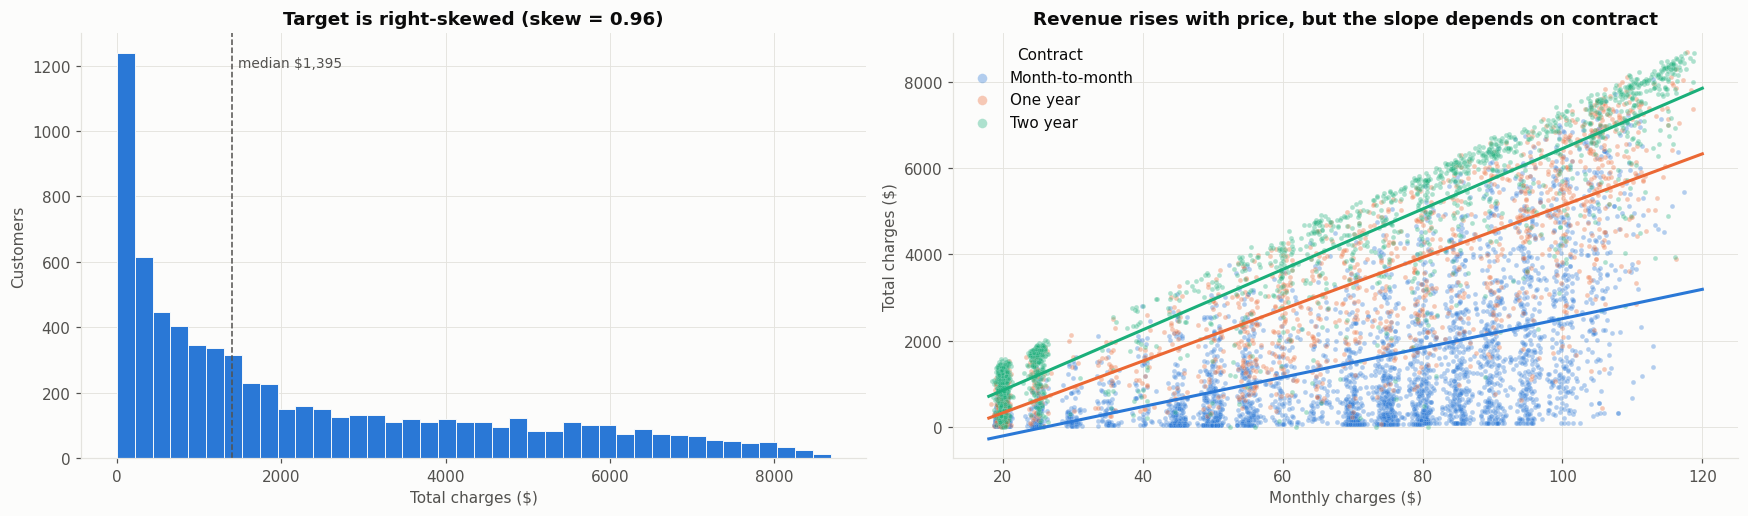

,total $ per $1 of monthly price
Contract,
Month-to-month,20.6
One year,46.6
Two year,61.0


In [5]:
# ---------------------------------------------------------------
# 3. Target distribution and its relationship with price and contract
# ---------------------------------------------------------------
TARGET = "TotalCharges"
print(df[TARGET].describe().round(2))

contract_order = ["Month-to-month", "One year", "Two year"]
contract_colors = dict(zip(contract_order, CAT[:3]))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))

ax = axes[0]
ax.hist(df[TARGET], bins=40, color=CAT[0], edgecolor=SURFACE, linewidth=0.6)
ax.axvline(df[TARGET].median(), color=INK_2, ls="--", lw=1)
ax.text(df[TARGET].median() + 80, ax.get_ylim()[1] * 0.92,
        f"median ${df[TARGET].median():,.0f}", color=INK_2, fontsize=9)
ax.set_xlabel("Total charges ($)")
ax.set_ylabel("Customers")
ax.set_title(f"Target is right-skewed (skew = {df[TARGET].skew():.2f})")

ax = axes[1]
for c in contract_order:
    sub = df[df["Contract"] == c]
    ax.scatter(sub["MonthlyCharges"], sub[TARGET], s=10, alpha=0.35, color=contract_colors[c],
               edgecolor=SURFACE, linewidth=0.2, label=c)
    slope = np.polyfit(sub["MonthlyCharges"], sub[TARGET], 1)
    xs = np.linspace(18, 120, 50)
    ax.plot(xs, np.polyval(slope, xs), color=contract_colors[c], lw=2)
ax.set_xlabel("Monthly charges ($)")
ax.set_ylabel("Total charges ($)")
ax.set_title("Revenue rises with price, but the slope depends on contract")
ax.legend(title="Contract", markerscale=2)

fig.tight_layout()
save(fig, "01_target_distribution.png")
plt.show()

# Average lifetime revenue per $ of monthly price, by contract
(df.groupby("Contract")[TARGET].sum() / df.groupby("Contract")["MonthlyCharges"].sum()).round(1).rename(
    "total $ per $1 of monthly price").to_frame()

**Observations**

* `TotalCharges` is **right-skewed**: many recent customers with small totals and a long tail of high-value customers.
* Lifetime revenue grows with the monthly price, but the **slope differs by contract**: each dollar of monthly price
  is worth far more for two-year customers than for month-to-month customers (because they stay much longer).
  A plain linear model gives `MonthlyCharges` **one** slope for everyone, so it cannot represent this.
  This is the key motivation for the **interaction features** engineered in Section 4.

## 4. Feature Engineering

We build two feature sets so the effect of feature engineering can be measured directly.

**Raw feature set** — the cleaned attributes as they are: one-hot encoded categorical columns + `MonthlyCharges`.

**Engineered feature set** — the raw set **plus** new features, each motivated by the EDA:

| New feature | Definition | Why it should help |
|---|---|---|
| `NumServices` | Number of services subscribed (from Deliverable 1) | Customers with more services are more "embedded" and stay longer |
| `ProtectionAddons` | Count of OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport | Deliverable 1 showed protective add-ons strongly linked to retention |
| `StreamingAddons` | Count of StreamingTV, StreamingMovies | Separates entertainment spend from protection spend |
| `AutoPay` | 1 if paying by automatic bank transfer or credit card | Automatic payers churned far less in Deliverable 1 |
| `FamilyAccount` | 1 if the customer has a partner **or** dependents | Combines two related household signals |
| `Contract × MonthlyCharges` (2 terms) | Monthly price multiplied by each contract dummy | Lets the price slope differ by contract (Section 3 scatter plot) |
| `AutoPay × MonthlyCharges` | Monthly price × automatic-payment flag | Lets price matter more for stable, auto-paying customers |
| `FamilyAccount × MonthlyCharges` | Monthly price × household flag | Same idea for household customers |
| `NumServices × MonthlyCharges` | Price × number of services | Captures "embedded and high-spend" customers |
| `MonthlyCharges²` | Squared monthly price | Allows a curved (non-linear) price effect |

All features are standardised inside each model pipeline, so the scaling is learned only from training folds.

In [6]:
# ---------------------------------------------------------------
# 4.1 Raw feature set: one-hot categoricals + MonthlyCharges
# ---------------------------------------------------------------
categorical_cols = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines",
                    "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
                    "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]

# drop_first=True avoids the "dummy variable trap" (perfect multicollinearity) in linear models
X_raw = pd.get_dummies(df[categorical_cols], drop_first=True, dtype=float)
X_raw["MonthlyCharges"] = df["MonthlyCharges"]
y = df[TARGET].copy()

# Deliberately EXCLUDED: tenure, tenure_group (leakage), Churn/Churn_flag (outcome), customerID (identifier)
print("Raw feature set:", X_raw.shape[1], "features")

Raw feature set: 21 features


In [7]:
# ---------------------------------------------------------------
# 4.2 Engineered feature set
# ---------------------------------------------------------------
X_eng = X_raw.copy()
mc = df["MonthlyCharges"]

# Count features
X_eng["NumServices"] = df["NumServices"]
X_eng["ProtectionAddons"] = df[["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]].eq("Yes").sum(axis=1)
X_eng["StreamingAddons"] = df[["StreamingTV", "StreamingMovies"]].eq("Yes").sum(axis=1)

# Combined flags
X_eng["AutoPay"] = df["PaymentMethod"].str.contains("automatic").astype(float)
X_eng["FamilyAccount"] = (df["Partner"].eq("Yes") | df["Dependents"].eq("Yes")).astype(float)

# Interaction terms: allow the effect of price to differ between customer types
X_eng["OneYear_x_Monthly"] = X_raw["Contract_One year"] * mc
X_eng["TwoYear_x_Monthly"] = X_raw["Contract_Two year"] * mc
X_eng["AutoPay_x_Monthly"] = X_eng["AutoPay"] * mc
X_eng["Family_x_Monthly"] = X_eng["FamilyAccount"] * mc
X_eng["NumServices_x_Monthly"] = X_eng["NumServices"] * mc

# Polynomial term: allow a curved price effect
X_eng["MonthlyCharges_sq"] = mc ** 2

new_features = [c for c in X_eng.columns if c not in X_raw.columns]
print("Engineered feature set:", X_eng.shape[1], "features  (", len(new_features), "new )")

# Correlation of each new feature with the target (quick check that they carry signal)
X_eng[new_features].corrwith(y).sort_values(ascending=False).round(3).rename("corr_with_TotalCharges").to_frame()

Engineered feature set: 32 features  ( 11 new )


,corr_with_TotalCharges
NumServices_x_Monthly,0.800
NumServices,0.776
MonthlyCharges_sq,0.693
ProtectionAddons,0.678
StreamingAddons,0.591
TwoYear_x_Monthly,0.584
Family_x_Monthly,0.542
AutoPay_x_Monthly,0.530
OneYear_x_Monthly,0.336
AutoPay,0.307


## 5. Train/Test Split and Model Definitions

* **80 / 20 split** (`random_state = 42`). The 20% **test set is locked away** and used once, at the end.
* All model selection uses **5-fold cross-validation on the training set only**.

**Models compared** (each wrapped in a pipeline with `StandardScaler`):

| Model | Type | Why it is included |
|---|---|---|
| Linear Regression | Multiple linear regression (OLS) | Interpretable baseline |
| Ridge Regression | L2-regularised linear | Shrinks correlated coefficients (multicollinearity found in Deliverable 1); `alpha` chosen by internal CV (`RidgeCV`) |
| Lasso Regression | L1-regularised linear | Shrinks **and** removes weak features (built-in feature selection); `alpha` chosen by internal CV (`LassoCV`) |
| Random Forest | Ensemble of decision trees | Captures non-linear effects and interactions automatically |
| Gradient Boosting | Sequential tree ensemble | Usually the strongest tabular model; checks whether linear models leave signal behind |

In [8]:
# ---------------------------------------------------------------
# 5.1 Hold-out split (same rows for both feature sets)
# ---------------------------------------------------------------
idx_train, idx_test = train_test_split(df.index, test_size=0.20, random_state=RANDOM_STATE)
print(f"Training rows: {len(idx_train):,}   Test rows: {len(idx_test):,}")
print(f"Mean TotalCharges - train: ${y.loc[idx_train].mean():,.0f}   test: ${y.loc[idx_test].mean():,.0f}")

Training rows: 5,634   Test rows: 1,409
Mean TotalCharges - train: $2,287   test: $2,250


In [9]:
# ---------------------------------------------------------------
# 5.2 Model pipelines
# ---------------------------------------------------------------
def make_models():
    # Fresh, unfitted model objects (called separately for each feature set)
    return {
        "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
        "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 61))),
        "Lasso": make_pipeline(StandardScaler(), LassoCV(alphas=np.logspace(-2, 3, 60), cv=5, max_iter=50000,
                                                          random_state=RANDOM_STATE)),
        "Random Forest": make_pipeline(StandardScaler(), RandomForestRegressor(
            n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE)),
        "Gradient Boosting": make_pipeline(StandardScaler(), GradientBoostingRegressor(
            n_estimators=300, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE)),
    }

MODEL_NAMES = list(make_models().keys())
MODEL_COLORS = dict(zip(MODEL_NAMES, CAT[:5]))     # fixed colour per model in every chart

## 6. Cross-Validation (5-fold) on Raw vs Engineered Features

Cross-validation estimates how well each model **generalises to unseen data**: the training set is split into 5 folds;
each model is trained on 4 folds and scored on the 5th, five times. We report the **mean and standard deviation** of:

* **R²** – share of variance in lifetime revenue explained (1.0 = perfect)
* **MSE** – mean squared error (\$²); penalises large errors heavily
* **RMSE** – square root of MSE, in dollars (typical size of an error)
* **MAE** – mean absolute error, in dollars (less sensitive to large errors)

In [10]:
# ---------------------------------------------------------------
# 6.1 Run 5-fold CV for every model on both feature sets
# ---------------------------------------------------------------
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"r2": "r2", "mse": "neg_mean_squared_error", "mae": "neg_mean_absolute_error"}

cv_rows, fold_rows = [], []
for set_name, X in [("Raw", X_raw), ("Engineered", X_eng)]:
    for name, model in make_models().items():
        start = time.time()
        res = cross_validate(model, X.loc[idx_train], y.loc[idx_train], cv=cv, scoring=scoring)
        mse = -res["test_mse"]
        rmse = np.sqrt(mse)                       # RMSE per fold
        cv_rows.append({
            "features": set_name, "model": name,
            "R2_mean": res["test_r2"].mean(), "R2_std": res["test_r2"].std(),
            "MSE_mean": mse.mean(),
            "RMSE_mean": rmse.mean(), "RMSE_std": rmse.std(),
            "MAE_mean": -res["test_mae"].mean(),
            "seconds": time.time() - start,
        })
        for k in range(cv.get_n_splits()):
            fold_rows.append({"features": set_name, "model": name, "fold": k + 1,
                              "R2": res["test_r2"][k], "RMSE": rmse[k]})

cv_results = pd.DataFrame(cv_rows)
fold_results = pd.DataFrame(fold_rows)

show = cv_results.copy()
show["R2 (mean ± std)"] = show.apply(lambda r: f"{r.R2_mean:.4f} ± {r.R2_std:.4f}", axis=1)
show["RMSE $ (mean ± std)"] = show.apply(lambda r: f"{r.RMSE_mean:,.1f} ± {r.RMSE_std:,.1f}", axis=1)
show["MSE"] = show["MSE_mean"].map("{:,.0f}".format)
show["MAE $"] = show["MAE_mean"].map("{:,.1f}".format)
show[["features", "model", "R2 (mean ± std)", "RMSE $ (mean ± std)", "MSE", "MAE $"]]

,features,model,R2 (mean ± std),RMSE $ (mean ± std),MSE,MAE $
0,Raw,Linear Regression,0.7441 ± 0.0094,"1,144.3 ± 18.9","1,309,746",898.6
1,Raw,Ridge,0.7442 ± 0.0094,"1,144.0 ± 18.7","1,309,057",898.0
2,Raw,Lasso,0.7441 ± 0.0094,"1,144.2 ± 18.7","1,309,480",898.5
3,Raw,Random Forest,0.7791 ± 0.0168,"1,062.5 ± 36.7","1,130,274",756.1
4,Raw,Gradient Boosting,0.7897 ± 0.0146,"1,036.9 ± 32.8","1,076,160",736.6
5,Engineered,Linear Regression,0.7918 ± 0.0103,"1,031.9 ± 22.2","1,065,253",741.6
6,Engineered,Ridge,0.7917 ± 0.0103,"1,032.2 ± 22.3","1,065,855",742.2
7,Engineered,Lasso,0.7917 ± 0.0103,"1,032.2 ± 22.1","1,065,839",742.2
8,Engineered,Random Forest,0.7754 ± 0.0156,"1,071.4 ± 34.4","1,149,187",761.4
9,Engineered,Gradient Boosting,0.7891 ± 0.0120,"1,038.5 ± 25.7","1,079,185",740.5


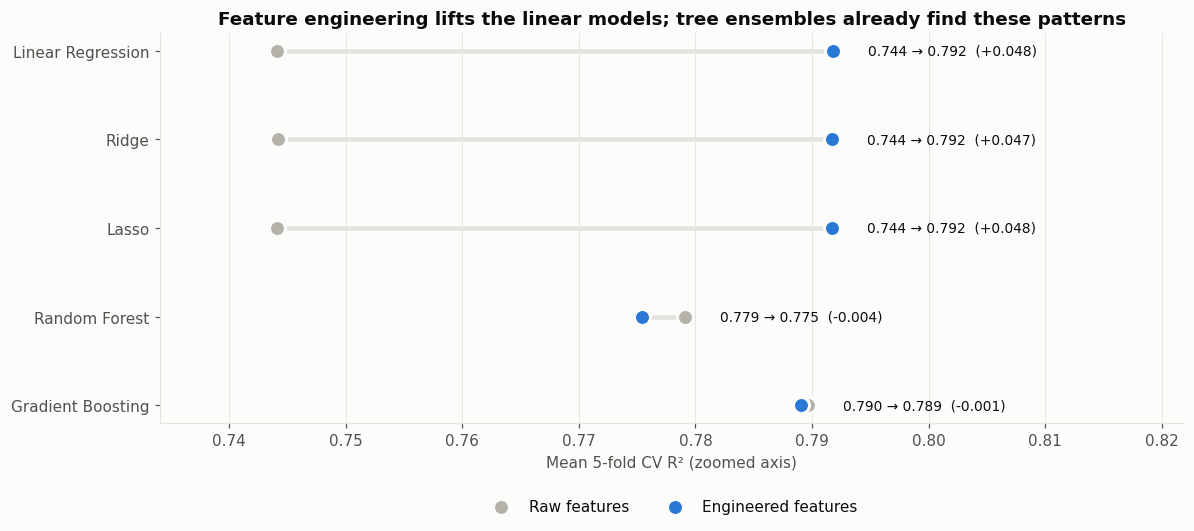

,R2 raw,R2 engineered,R2 gain,RMSE raw $,RMSE engineered $,RMSE reduction $
model,,,,,,
Linear Regression,0.7441,0.7918,0.0477,1144.2852,1031.8732,112.4120
Ridge,0.7442,0.7917,0.0475,1143.9871,1032.1622,111.8250
Lasso,0.7441,0.7917,0.0476,1144.1714,1032.1578,112.0136
Random Forest,0.7791,0.7754,-0.0037,1062.5103,1071.4486,-8.9383
Gradient Boosting,0.7897,0.7891,-0.0006,1036.8620,1038.5212,-1.6592


In [11]:
# ---------------------------------------------------------------
# 6.2 Effect of feature engineering on each model (cross-validated R^2)
# ---------------------------------------------------------------
pivot_r2 = cv_results.pivot(index="model", columns="features", values="R2_mean").reindex(MODEL_NAMES)
pivot_rmse = cv_results.pivot(index="model", columns="features", values="RMSE_mean").reindex(MODEL_NAMES)
fe_gain = pd.DataFrame({
    "R2 raw": pivot_r2["Raw"], "R2 engineered": pivot_r2["Engineered"],
    "R2 gain": pivot_r2["Engineered"] - pivot_r2["Raw"],
    "RMSE raw $": pivot_rmse["Raw"], "RMSE engineered $": pivot_rmse["Engineered"],
    "RMSE reduction $": pivot_rmse["Raw"] - pivot_rmse["Engineered"],
})

# Dumbbell chart: grey dot = raw features, blue dot = engineered features, line = change
fig, ax = plt.subplots(figsize=(12, 4.6))
ypos = np.arange(len(MODEL_NAMES))[::-1]
for yv, name in zip(ypos, MODEL_NAMES):
    r, e = pivot_r2.loc[name, "Raw"], pivot_r2.loc[name, "Engineered"]
    ax.plot([r, e], [yv, yv], color=GRID, lw=3, zorder=1)
    ax.scatter(r, yv, s=110, color=MUTED, edgecolor=SURFACE, linewidth=2, zorder=3,
               label="Raw features" if yv == ypos[0] else None)
    ax.scatter(e, yv, s=110, color=CAT[0], edgecolor=SURFACE, linewidth=2, zorder=3,
               label="Engineered features" if yv == ypos[0] else None)
    ax.text(max(r, e) + 0.003, yv, f"{r:.3f} → {e:.3f}  ({e - r:+.3f})", va="center", fontsize=9)
ax.set_yticks(ypos, MODEL_NAMES)
ax.set_xlim(pivot_r2.values.min() - 0.01, pivot_r2.values.max() + 0.03)
ax.set_xlabel("Mean 5-fold CV R² (zoomed axis)")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
ax.set_title("Feature engineering lifts the linear models; tree ensembles already find these patterns")
save(fig, "02_feature_engineering_impact.png")
plt.show()

fe_gain.round(4)

### 6.3 Interpreting the cross-validation results

*(numbers from the tables above)*

* **Raw features:** the three linear models score almost identically (R² ≈ **0.744**, RMSE ≈ **\$1,144**). Ridge and
  Lasso barely differ from ordinary least squares because there are ~5,600 training rows for only 21 features, so there
  is little overfitting for regularisation to fix. The tree ensembles do better on raw data (Random Forest 0.779,
  Gradient Boosting **0.790**) because they can model interactions on their own.
* **Engineered features:** the linear models jump to R² ≈ **0.792** (+0.048) and RMSE falls by about **\$112** (to
  ≈ \$1,032); MAE falls from ≈ \$898 to ≈ \$742. The interaction terms give the linear models the "price slope depends on
  contract" structure seen in Section 3.
* **Tree models do not benefit** (Random Forest 0.779 → 0.775, Gradient Boosting 0.790 → 0.789). A tree can already split
  on contract first and then on price, so the engineered interactions are redundant for it.
* With engineered features, the **simple linear models catch up with Gradient Boosting**.
* Fold-to-fold standard deviations are small (≈ 0.01 in R²), so the results are stable. Random Forest varies the most
  between folds (≈ 0.016).

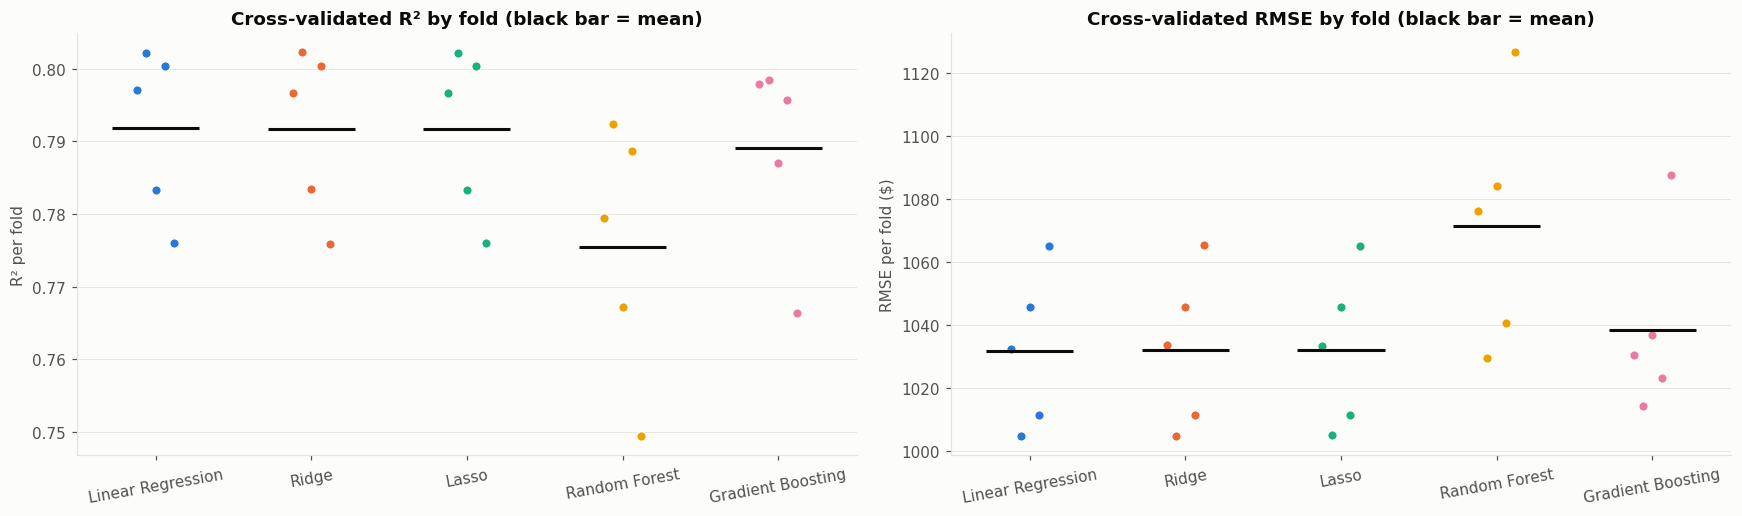

In [12]:
# ---------------------------------------------------------------
# 6.4 Fold-by-fold stability of each model (engineered features)
# ---------------------------------------------------------------
eng_folds = fold_results[fold_results["features"] == "Engineered"]
eng_cv = cv_results[cv_results["features"] == "Engineered"].set_index("model").reindex(MODEL_NAMES)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, metric, label in [(axes[0], "R2", "R² per fold"), (axes[1], "RMSE", "RMSE per fold ($)")]:
    for i, name in enumerate(MODEL_NAMES):
        vals = eng_folds.loc[eng_folds["model"] == name, metric].values
        jitter = np.linspace(-0.12, 0.12, len(vals))
        ax.scatter(np.full(len(vals), i) + jitter, vals, s=40, color=MODEL_COLORS[name],
                   edgecolor=SURFACE, linewidth=1, zorder=3)
        ax.hlines(vals.mean(), i - 0.28, i + 0.28, color=INK, lw=2, zorder=4)
    ax.set_xticks(range(len(MODEL_NAMES)), MODEL_NAMES, rotation=10)
    ax.set_ylabel(label)
    ax.grid(axis="x", visible=False)
axes[0].set_title("Cross-validated R² by fold (black bar = mean)")
axes[1].set_title("Cross-validated RMSE by fold (black bar = mean)")
fig.tight_layout()
save(fig, "03_cv_fold_stability.png")
plt.show()

## 7. Hold-out Test Evaluation

Each model is now refit on the **full training set (engineered features)** and evaluated **once** on the untouched
20% test set. Agreement between CV scores and test scores shows the models generalise rather than overfit.

In [13]:
# ---------------------------------------------------------------
# 7.1 Fit on the training set, score on the test set
# ---------------------------------------------------------------
fitted, test_rows, test_preds = {}, [], {}
X_tr, X_te = X_eng.loc[idx_train], X_eng.loc[idx_test]
y_tr, y_te = y.loc[idx_train], y.loc[idx_test]

for name, model in make_models().items():
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    fitted[name], test_preds[name] = model, pred
    mse = mean_squared_error(y_te, pred)
    test_rows.append({
        "model": name,
        "Test R2": r2_score(y_te, pred),
        "Test MSE": mse,
        "Test RMSE $": np.sqrt(mse),
        "Test MAE $": mean_absolute_error(y_te, pred),
        "CV R2 (train)": eng_cv.loc[name, "R2_mean"],
        "Train R2": r2_score(y_tr, model.predict(X_tr)),
    })

test_results = pd.DataFrame(test_rows).set_index("model")
test_results["RMSE as % of mean revenue"] = test_results["Test RMSE $"] / y_te.mean() * 100
fmt = {"Test R2": "{:.4f}", "Test MSE": "{:,.0f}", "Test RMSE $": "{:,.1f}", "Test MAE $": "{:,.1f}",
       "CV R2 (train)": "{:.4f}", "Train R2": "{:.4f}", "RMSE as % of mean revenue": "{:.1f}%"}
# Format numbers as text for a readable table (best model = highest Test R2)
test_results.sort_values("Test R2", ascending=False).apply(
    lambda col: col.map(fmt[col.name].format))

,Test R2,Test MSE,Test RMSE $,Test MAE $,CV R2 (train),Train R2,RMSE as % of mean revenue
model,,,,,,,
Gradient Boosting,0.8010,"1,035,222","1,017.5",731.6,0.7891,0.8246,45.2%
Linear Regression,0.8001,"1,039,729","1,019.7",738.0,0.7918,0.7944,45.3%
Ridge,0.8001,"1,039,888","1,019.7",736.5,0.7917,0.7945,45.3%
Lasso,0.8000,"1,040,318","1,020.0",736.9,0.7917,0.7946,45.3%
Random Forest,0.7886,"1,100,043","1,048.8",740.2,0.7754,0.8768,46.6%


In [14]:
# ---------------------------------------------------------------
# 7.2 Regularisation strength chosen by Ridge and Lasso, and features Lasso removed
# ---------------------------------------------------------------
ridge = fitted["Ridge"][-1]
lasso = fitted["Lasso"][-1]
lasso_coef = pd.Series(lasso.coef_, index=X_eng.columns)
print(f"Ridge alpha chosen by CV : {ridge.alpha_:.4g}")
print(f"Lasso alpha chosen by CV : {lasso.alpha_:.4g}")
print(f"Lasso kept {int((lasso_coef != 0).sum())} of {len(lasso_coef)} features; "
      f"removed (coefficient = 0): {list(lasso_coef[lasso_coef == 0].index)}")

Ridge alpha chosen by CV : 5.012
Lasso alpha chosen by CV : 0.104
Lasso kept 28 of 32 features; removed (coefficient = 0): ['StreamingMovies_Yes', 'PaymentMethod_Electronic check', 'NumServices', 'ProtectionAddons']


## 8. Visual Comparison of Model Performance

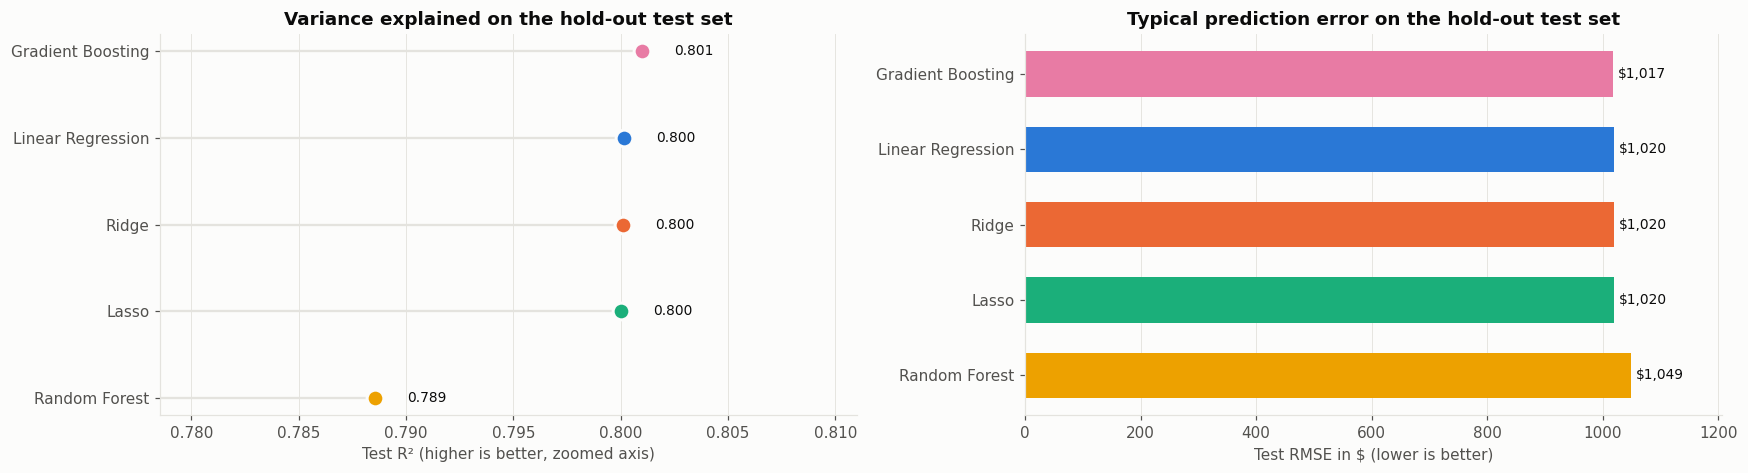

In [15]:
# ---------------------------------------------------------------
# 8.1 Test-set R^2 and RMSE side by side
# ---------------------------------------------------------------
order = test_results.sort_values("Test R2").index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(16, 4.4))

ax = axes[0]
# Dot plot (not bars) so a zoomed axis does not exaggerate differences
for i, m in enumerate(order):
    v = test_results.loc[m, "Test R2"]
    ax.hlines(i, test_results["Test R2"].min() - 0.01, v, color=GRID, lw=1.5, zorder=1)
    ax.scatter(v, i, s=120, color=MODEL_COLORS[m], edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.text(v + 0.0015, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_yticks(range(len(order)), order)
ax.set_xlim(test_results["Test R2"].min() - 0.01, test_results["Test R2"].max() + 0.01)
ax.set_xlabel("Test R² (higher is better, zoomed axis)")
ax.grid(axis="y", visible=False)
ax.set_title("Variance explained on the hold-out test set")

ax = axes[1]
ax.barh(order, test_results.loc[order, "Test RMSE $"], color=[MODEL_COLORS[m] for m in order], height=0.6)
for i, m in enumerate(order):
    v = test_results.loc[m, "Test RMSE $"]
    ax.text(v + 8, i, f"${v:,.0f}", va="center", fontsize=9)
ax.set_xlim(0, test_results["Test RMSE $"].max() * 1.15)
ax.set_xlabel("Test RMSE in $ (lower is better)")
ax.grid(axis="y", visible=False)
ax.set_title("Typical prediction error on the hold-out test set")

fig.tight_layout()
save(fig, "04_test_metrics_comparison.png")
plt.show()

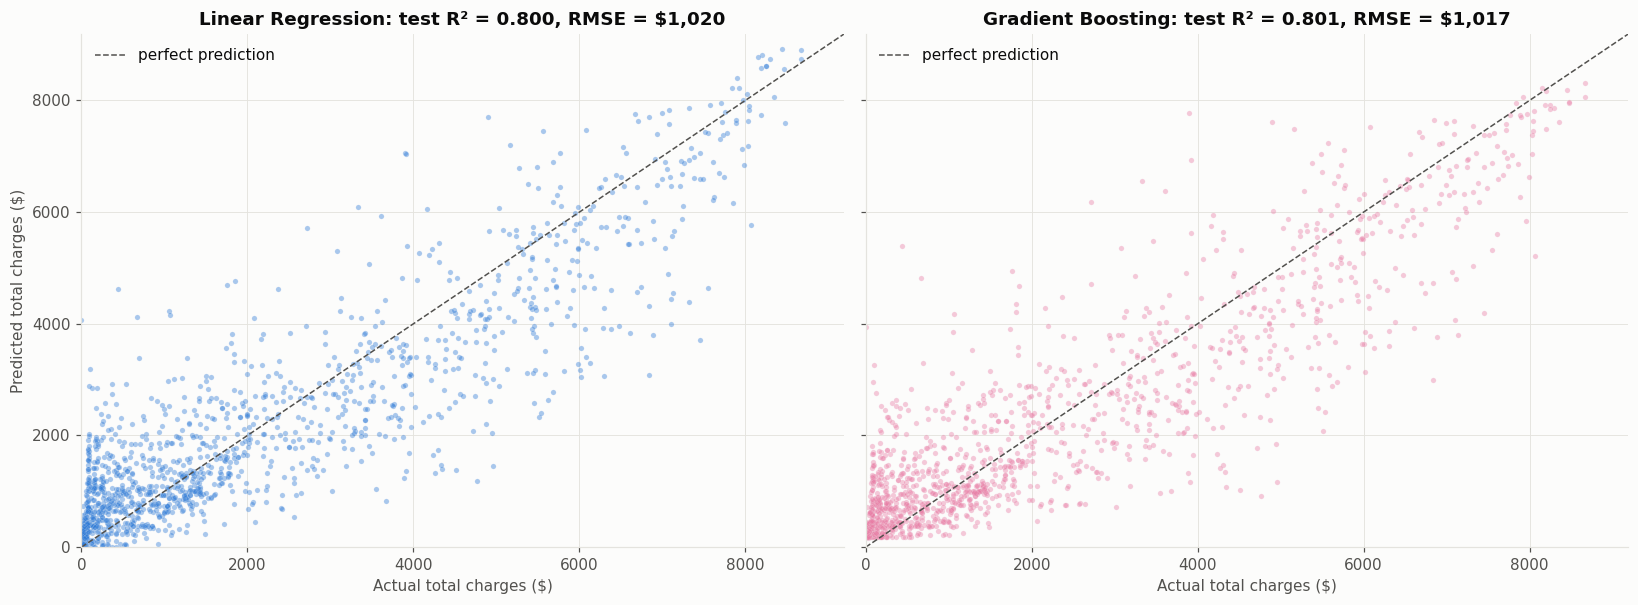

In [16]:
# ---------------------------------------------------------------
# 8.2 Predicted vs actual: best linear model vs best overall model
# ---------------------------------------------------------------
best_overall = test_results["Test R2"].idxmax()
linear_family = ["Linear Regression", "Ridge", "Lasso"]
best_linear = test_results.loc[linear_family, "Test R2"].idxmax()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), sharex=True, sharey=True)
lim = [0, max(y_te.max(), max(test_preds[best_overall].max(), test_preds[best_linear].max())) * 1.03]
for ax, name in zip(axes, [best_linear, best_overall]):
    ax.scatter(y_te, test_preds[name], s=12, alpha=0.4, color=MODEL_COLORS[name],
               edgecolor=SURFACE, linewidth=0.2)
    ax.plot(lim, lim, color=INK_2, ls="--", lw=1, label="perfect prediction")
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_xlabel("Actual total charges ($)")
    ax.set_title(f"{name}: test R² = {test_results.loc[name, 'Test R2']:.3f}, "
                 f"RMSE = ${test_results.loc[name, 'Test RMSE $']:,.0f}")
    ax.legend(loc="upper left")
axes[0].set_ylabel("Predicted total charges ($)")
fig.tight_layout()
save(fig, "05_predicted_vs_actual.png")
plt.show()

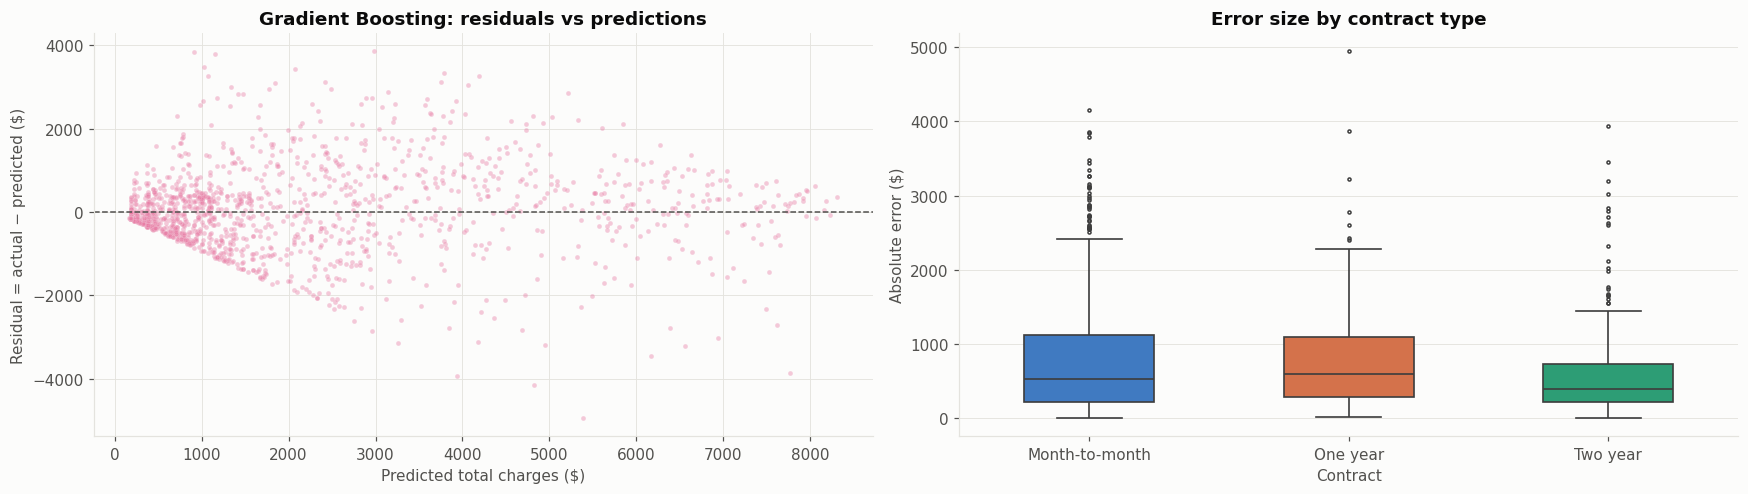

Mean absolute error by contract (test set):
Contract
Month-to-month    789.0
One year          788.0
Two year          562.0
Name: TotalCharges, dtype: float64


In [17]:
# ---------------------------------------------------------------
# 8.3 Residual analysis for the best model
# ---------------------------------------------------------------
resid = y_te - test_preds[best_overall]
contract_test = df.loc[idx_test, "Contract"]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
ax = axes[0]
ax.scatter(test_preds[best_overall], resid, s=10, alpha=0.4, color=MODEL_COLORS[best_overall],
           edgecolor=SURFACE, linewidth=0.2)
ax.axhline(0, color=INK_2, ls="--", lw=1)
ax.set_xlabel("Predicted total charges ($)")
ax.set_ylabel("Residual = actual − predicted ($)")
ax.set_title(f"{best_overall}: residuals vs predictions")

ax = axes[1]
sns.boxplot(x=contract_test, y=resid.abs(), order=contract_order, hue=contract_test, hue_order=contract_order,
            palette=contract_colors, legend=False, width=0.5, fliersize=2, linewidth=1.1, ax=ax)
ax.set_xlabel("Contract")
ax.set_ylabel("Absolute error ($)")
ax.set_title("Error size by contract type")
fig.tight_layout()
save(fig, "06_residual_analysis.png")
plt.show()

print("Mean absolute error by contract (test set):")
print(resid.abs().groupby(contract_test).mean().reindex(contract_order).round(0))

## 9. Model Interpretation: What Drives Lifetime Revenue?

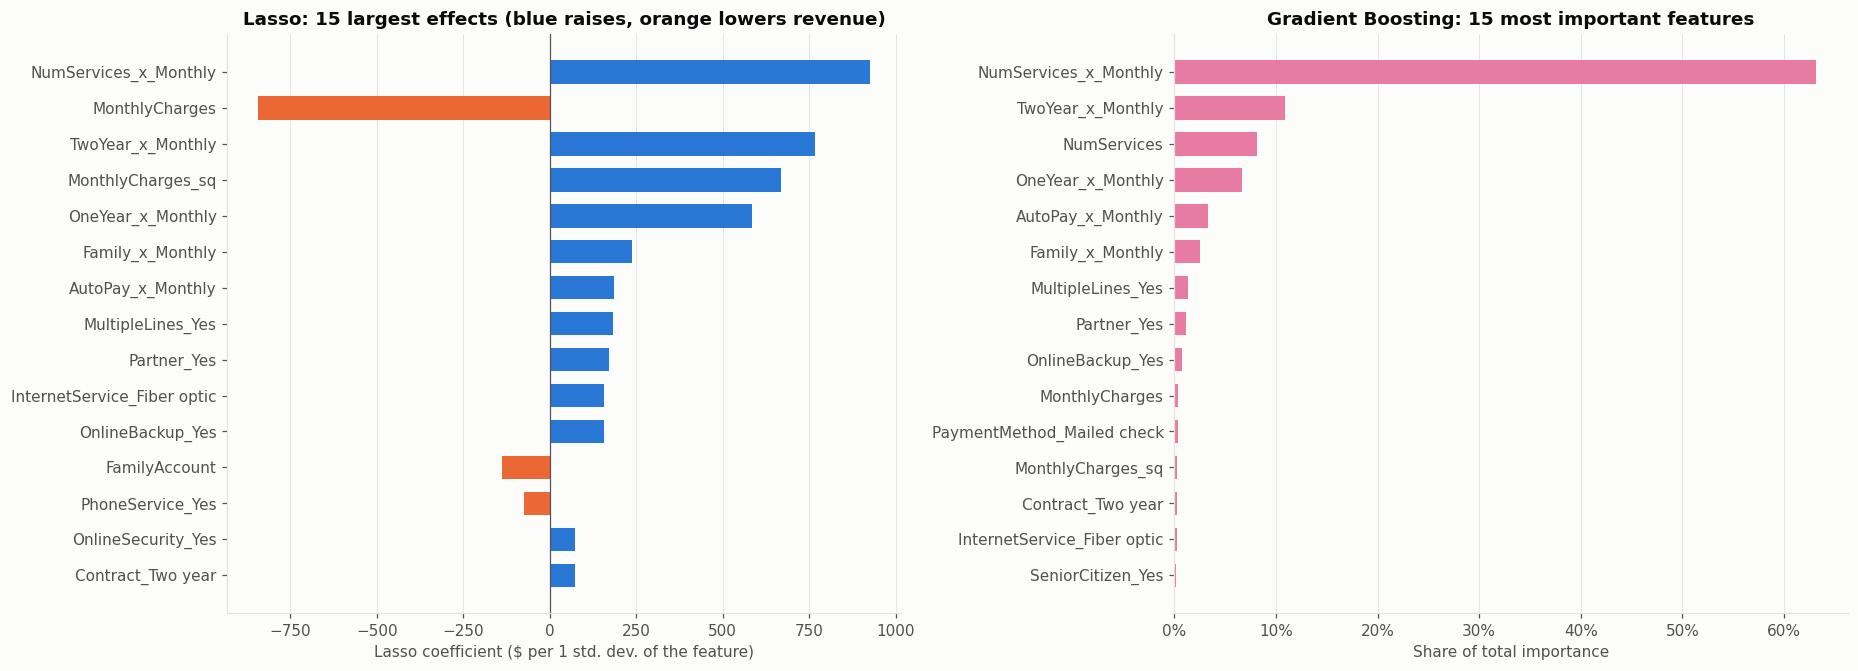

Top 8 Gradient Boosting features:
NumServices_x_Monthly    63.1%
TwoYear_x_Monthly        10.8%
NumServices               8.1%
OneYear_x_Monthly         6.6%
AutoPay_x_Monthly         3.3%
Family_x_Monthly          2.5%
MultipleLines_Yes         1.3%
Partner_Yes               1.1%
dtype: object


In [18]:
# ---------------------------------------------------------------
# 9.1 Lasso coefficients (standardised) and Gradient Boosting importances
# ---------------------------------------------------------------
gb = fitted["Gradient Boosting"][-1]
gb_imp = pd.Series(gb.feature_importances_, index=X_eng.columns).sort_values(ascending=False)
top_coef = lasso_coef[lasso_coef != 0].reindex(lasso_coef[lasso_coef != 0].abs().sort_values(ascending=False).index)[:15]

fig, axes = plt.subplots(1, 2, figsize=(17, 6.2))
ax = axes[0]
tc = top_coef[::-1]
ax.barh(tc.index, tc.values, color=[CAT[0] if v > 0 else CAT[1] for v in tc.values], height=0.65)
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_xlabel("Lasso coefficient ($ per 1 std. dev. of the feature)")
ax.grid(axis="y", visible=False)
ax.set_title("Lasso: 15 largest effects (blue raises, orange lowers revenue)")

ax = axes[1]
ti = gb_imp[:15][::-1]
ax.barh(ti.index, ti.values, color=MODEL_COLORS["Gradient Boosting"], height=0.65)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Share of total importance")
ax.grid(axis="y", visible=False)
ax.set_title("Gradient Boosting: 15 most important features")
fig.tight_layout()
save(fig, "07_feature_importance.png")
plt.show()

print("Top 8 Gradient Boosting features:")
print((gb_imp[:8] * 100).round(1).astype(str) + "%")

**Observations**

* Both models agree on the main drivers. The most important feature is **`NumServices × MonthlyCharges`**:
  customers who buy many services at a higher price are the ones who have stayed longest and generated the most
  revenue. Next come the **contract × price** interactions: a dollar of monthly price is worth far more on a one- or
  two-year contract than month-to-month.
* Lasso gives `MonthlyCharges` on its own a **negative** coefficient. This does **not** mean higher prices lower
  revenue. Price also appears in five interaction terms and a squared term, so its total effect is the sum of all of
  them (which is strongly positive). This is a textbook symptom of multicollinearity, and the reason we judge the models
  on predictions rather than on individual coefficients.
* Lasso set 4 features to exactly zero (`NumServices`, `ProtectionAddons`, `StreamingMovies_Yes`,
  `PaymentMethod_Electronic check`), because their information is already carried by the interaction terms and
  other features.
* Demographics (partner, senior citizen) add little once a customer's plan is known.

## 10. Summary of Results

### 10.1 Which model performed best?

| Model (engineered features) | 5-fold CV R² | Test R² | Test RMSE | Test MAE | Train R² |
|---|---|---|---|---|---|
| **Gradient Boosting** | 0.789 | **0.801** | **\$1,017.5** | **\$731.6** | 0.825 |
| **Ridge** | **0.792** | 0.800 | \$1,019.7 | \$736.5 | 0.795 |
| Lasso | 0.792 | 0.800 | \$1,020.0 | \$736.9 | 0.795 |
| Linear Regression | 0.792 | 0.800 | \$1,019.7 | \$738.0 | 0.794 |
| Random Forest | 0.775 | 0.789 | \$1,048.8 | \$740.2 | 0.877 |

* **Gradient Boosting** has the best test score, but only by **0.001 R² (about \$2 of RMSE)** over the engineered
  Ridge model — a practical tie.
* **Recommended model: Ridge regression on the engineered features.** It matches Gradient Boosting's accuracy, has
  the best cross-validated R², and its train, CV and test scores are almost identical (0.795 / 0.792 / 0.800), which
  shows it generalises without overfitting. It is also fast and explainable to business users.
* **Random Forest generalised worst:** train R² 0.877 vs test 0.789, the largest gap, i.e. some overfitting.

### 10.2 Key insights

1. **Feature engineering mattered more than the choice of algorithm.** Engineered features improved the linear models
   by +0.048 R² (−\$112 RMSE), while the top four models differ by less than 0.002 R².
2. **Contract length multiplies customer value.** Each \$1 of monthly price corresponds to about \$21 of lifetime
   revenue on month-to-month contracts, \$47 on one-year and \$61 on two-year contracts.
3. **Bundled customers are the most valuable.** Number of services × price is the strongest single predictor.
4. **Revenue is easiest to predict for two-year customers** (mean absolute error ≈ \$562 vs ≈ \$789 for the other
   contracts), because long contracts make the customer's future predictable.
5. **Remaining error is large (RMSE ≈ 45% of average revenue).** Lifetime revenue depends mostly on *how long* a
   customer stays, which plan and profile only partly reveal. That uncertainty is exactly what the churn model in
   Deliverable 3 addresses.
6. **Regularisation changed little here** (Ridge `alpha` ≈ 5, Lasso `alpha` ≈ 0.10) because the data has many more rows
   than features; its main value was confirming which engineered features are redundant.

## 11. Challenges Encountered and How They Were Addressed

| Challenge | How it was addressed |
|---|---|
| **The planned target was trivial.** `MonthlyCharges` is almost fully determined by the services bought (CV R² ≈ 0.999), so every model would tie. | Ran sanity checks before modelling and switched to a target with real uncertainty: lifetime revenue (`TotalCharges`). |
| **Target leakage.** `TotalCharges ≈ tenure × MonthlyCharges`, so including `tenure` gives R² ≈ 0.999 without learning anything useful. | Removed `tenure` and `tenure_group` from the predictors, and also `Churn` (an outcome, and Deliverable 3's target). |
| **A single price slope for every customer.** The EDA scatter showed revenue-per-dollar differs by contract, which a linear model cannot express. | Engineered interaction terms (`Contract × MonthlyCharges`, etc.) and count features; measured their effect with a raw-vs-engineered comparison. |
| **Multicollinearity** (one-hot dummies, price and service counts are correlated). | Used `drop_first` encoding and compared OLS with Ridge (L2) and Lasso (L1); regularisation strength was chosen automatically by internal cross-validation. |
| **Fair, honest evaluation.** | Locked a 20% test set away; all comparisons used 5-fold CV on the training data; scaling was fitted inside each pipeline so no test information leaked into training. |
| **Skewed target with large values** (many small totals, long tail up to ~\$8,700). | Reported RMSE alongside MAE and R², and examined residuals by contract to see where errors concentrate. |

## 12. Conclusion and Next Steps

We built and compared five regression models to estimate customer lifetime revenue from plan and profile data,
evaluated them with R², MSE, RMSE and MAE using 5-fold cross-validation and a hold-out test set, and showed that
**well-designed features let a simple, interpretable Ridge model match a Gradient Boosting ensemble (test R² ≈ 0.80)**.

**Practical use:** the predicted value of each customer can be combined with the churn probability from Deliverable 3
to estimate **revenue at risk** (value × probability of leaving), so retention offers go first to customers who are both
valuable and likely to leave.

**Next (Deliverable 3):** classification models for `Churn` with hyperparameter tuning, customer clustering, and
association rule mining.